# What is an audio codec? The experiments

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/01-what-is-an-audio-codec/notebook.ipynb)

Companion to the article *What Is an Audio Codec? From MP3 to the Tokens Behind AI Music*. Every number in the article comes from the cells below. Run them, change them, and listen.

Runs on a CPU in under a minute. No GPU needed.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr

## 1. Sampling and aliasing

A sample rate of R can represent frequencies up to R/2. A tone above that limit does not disappear: it comes back as a false tone at R − f.

In [3]:
sr = 44100
n = np.arange(sr)                                  # one second of sample positions
for f in (30000, 25000):
    x = np.sin(2 * np.pi * f * n / sr)             # a tone above the 22,050 Hz limit
    found = np.abs(np.fft.rfft(x)).argmax()        # strongest frequency in the sampled signal
    print(f"{f} Hz tone sampled at {sr} Hz shows up at {found} Hz  (R - f = {sr - f})")

30000 Hz tone sampled at 44100 Hz shows up at 14100 Hz  (R - f = 14100)
25000 Hz tone sampled at 44100 Hz shows up at 19100 Hz  (R - f = 19100)


## 2. Bit depth and quantization noise

Rounding each sample to one of 2^bits levels adds noise. Each bit is worth about 6 dB.

In [4]:
def quantize(x, bits):                             # x between -1 and 1
    levels = 2 ** (bits - 1) - 1
    return np.round(x * levels) / levels

def snr_db(clean, noisy):
    return 10 * np.log10((clean ** 2).sum() / ((clean - noisy) ** 2).sum())

tone = np.sin(2 * np.pi * 997 * np.arange(2 * sr) / sr)
for bits in (4, 8, 12, 16):
    print(f"{bits:2d} bits: measured SNR {snr_db(tone, quantize(tone, bits)):5.1f} dB   rule 6.02 x bits + 1.76 = {6.02 * bits + 1.76:5.1f} dB")

 4 bits: measured SNR  25.1 dB   rule 6.02 x bits + 1.76 =  25.8 dB
 8 bits: measured SNR  49.9 dB   rule 6.02 x bits + 1.76 =  49.9 dB
12 bits: measured SNR  74.0 dB   rule 6.02 x bits + 1.76 =  74.0 dB
16 bits: measured SNR  98.1 dB   rule 6.02 x bits + 1.76 =  98.1 dB


Listen to it on music. At 4 bits the hiss is obvious.

In [5]:
music, msr = clip("fishin", offset=30, duration=8)
for bits in (16, 8, 4):
    print(f"{bits} bits"); display(Audio(quantize(music, bits), rate=msr))

16 bits


[audio player: run the cell to listen]


8 bits


[audio player: run the cell to listen]


4 bits


[audio player: run the cell to listen]


## 3. Lossless compression: store only the surprise

Predict each sample from the previous ones and store the difference. Entropy tells us how many bits per sample are needed on average.

In [6]:
v = np.array([100, 104, 109, 113, 116])
print("samples                         ", v)
print("residual, 'same as previous'    ", v[1:] - v[:-1])
print("residual, 'continue the line'   ", v[2:] - (2 * v[1:-1] - v[:-2]))

def entropy_bits(values):
    _, counts = np.unique(values, return_counts=True)
    p = counts / counts.sum()
    return -(p * np.log2(p)).sum()

for name in ("trumpet", "choice", "brahms", "fishin", "libri1"):
    y, _ = clip(name, duration=30)
    s = np.round(y * 32767).astype(np.int64)                 # 16-bit samples
    prev = s[1:] - s[:-1]
    line = s[2:] - (2 * s[1:-1] - s[:-2])
    print(f"{name:8s} raw {entropy_bits(s):5.2f} bits   same-as-previous {entropy_bits(prev):5.2f}   continue-the-line {entropy_bits(line):5.2f}")

samples                          [100 104 109 113 116]
residual, 'same as previous'     [4 5 4 3]
residual, 'continue the line'    [ 1 -1 -1]
trumpet  raw 10.24 bits   same-as-previous  8.20   continue-the-line  6.85
choice   raw 11.85 bits   same-as-previous  8.33   continue-the-line  8.35


brahms   raw 13.32 bits   same-as-previous 10.62   continue-the-line  9.56
fishin   raw 14.07 bits   same-as-previous 10.96   continue-the-line 10.88
libri1   raw 13.23 bits   same-as-previous 10.77   continue-the-line 10.16


## 4. Music is compact in the frequency domain

Cut the audio into blocks of 2,048 samples, transform each, and count how many coefficients hold 99% of the energy.

In [7]:
from scipy.fft import dct
for name in ("choice", "fishin", "brahms"):
    y, _ = clip(name, duration=20)
    blocks = y[: len(y) // 2048 * 2048].reshape(-1, 2048)
    coeffs = dct(blocks, norm="ortho", axis=1)
    energy = np.sort(coeffs ** 2, axis=1)[:, ::-1]
    cumulative = np.cumsum(energy, axis=1) / energy.sum(axis=1, keepdims=True)
    needed = np.median((cumulative < 0.99).sum(axis=1) + 1)
    print(f"{name:8s} {needed:4.0f} of 2048 coefficients hold 99% of the energy ({100 * needed / 2048:.1f}%)")

choice     70 of 2048 coefficients hold 99% of the energy (3.4%)


fishin     96 of 2048 coefficients hold 99% of the energy (4.7%)
brahms    165 of 2048 coefficients hold 99% of the energy (8.1%)


## 5. What the ear cannot hear

The threshold in quiet (Terhardt's formula), the Bark scale (Zwicker and Terhardt), and a simplified masking model: at the masker the threshold is `level − 14.5 − Bark`, falling 25 dB per Bark below it and 10 dB per Bark above.

  700 Hz: in quiet   4.7 dB, with the tone   4.7 dB
  850 Hz: in quiet   4.0 dB, with the tone  31.8 dB
 1000 Hz: in quiet   3.4 dB, with the tone  57.0 dB
 1170 Hz: in quiet   2.8 dB, with the tone  46.8 dB
 1370 Hz: in quiet   2.1 dB, with the tone  36.2 dB
 2000 Hz: in quiet  -0.3 dB, with the tone  11.1 dB
bits needed in the masker's band: (80 - 57) / 6.02 = 3.8


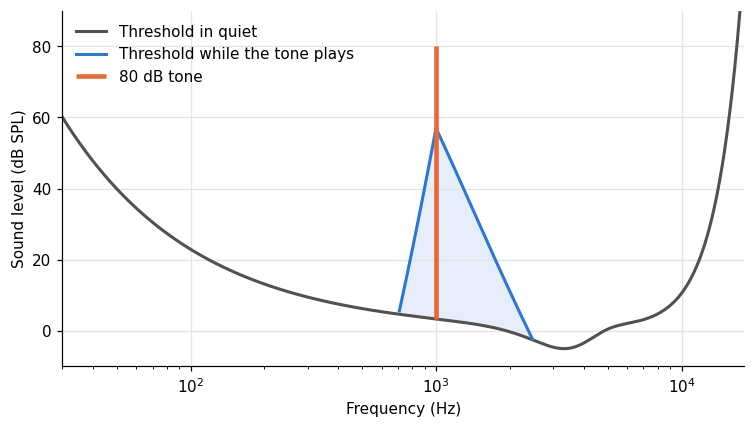

In [8]:
threshold_quiet = lambda f: 3.64 * (f / 1000) ** -0.8 - 6.5 * np.exp(-0.6 * (f / 1000 - 3.3) ** 2) + 1e-3 * (f / 1000) ** 4
bark = lambda f: 13 * np.arctan(0.00076 * f) + 3.5 * np.arctan((f / 7500) ** 2)

LEVEL, MASKER = 80.0, 1000.0                      # try other values
def masked_threshold(f):
    dz = bark(f) - bark(MASKER)
    return LEVEL - 14.5 - bark(MASKER) - np.where(dz < 0, 25 * -dz, 10 * dz)

for f in (700, 850, 1000, 1170, 1370, 2000):
    print(f"{f:5d} Hz: in quiet {threshold_quiet(f):5.1f} dB, with the tone {max(float(masked_threshold(f)), threshold_quiet(f)):5.1f} dB")
print(f"bits needed in the masker's band: ({LEVEL:.0f} - {float(masked_threshold(MASKER)):.0f}) / 6.02 = {(LEVEL - float(masked_threshold(MASKER))) / 6.02:.1f}")

f = np.geomspace(30, 18000, 800)
hidden = masked_threshold(f) > threshold_quiet(f)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(f, threshold_quiet(f), color=INK2, label="Threshold in quiet")
ax.plot(f[hidden], masked_threshold(f)[hidden], color=BLUE, label="Threshold while the tone plays")
ax.fill_between(f[hidden], threshold_quiet(f)[hidden], masked_threshold(f)[hidden], color=BLUE, alpha=0.12)
ax.vlines(MASKER, threshold_quiet(MASKER), LEVEL, color=ORANGE, lw=3, label=f"{LEVEL:.0f} dB tone")
ax.set_xscale("log"); ax.set_xlim(30, 18000); ax.set_ylim(-10, 90)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Sound level (dB SPL)"); ax.legend(frameon=False); plt.show()

## 6. Hiding noise: same amount, different sound

Two versions of the same clip with exactly the same amount of added noise (20 dB SNR). In the first the noise is white. In the second it follows the music's own spectrum from moment to moment. Listen to both.

In [9]:
from scipy.signal import stft, istft
rng = np.random.default_rng(0)
y, s = clip("fishin", offset=30, duration=10)

def scale_to_snr(noise, target_db=20):
    return noise * np.sqrt((y ** 2).sum() / 10 ** (target_db / 10) / (noise ** 2).sum())

white = scale_to_snr(rng.standard_normal(len(y)))
_, _, Y = stft(y, s, nperseg=2048)
_, _, W = stft(rng.standard_normal(len(y)), s, nperseg=2048)
_, shaped = istft(W * np.abs(Y), s, nperseg=2048)          # noise with the music's spectrum
shaped = scale_to_snr(shaped[: len(y)])

print(f"SNR white {snr_db(y, y + white):.2f} dB, shaped {snr_db(y, y + shaped):.2f} dB")
for label, audio in (("original", y), ("white noise", y + white), ("shaped noise", y + shaped)):
    print(label); display(Audio(audio, rate=s))

SNR white 20.00 dB, shaped 20.00 dB
original


[audio player: run the cell to listen]


white noise


[audio player: run the cell to listen]


shaped noise


[audio player: run the cell to listen]


## 7. MP3: what goes first when bits run short

Needs `ffmpeg` (preinstalled on Colab). We encode a mono clip at four bitrates and measure the highest frequency that survives.

In [10]:
import shutil, subprocess, os, soundfile as sf

def mp3_roundtrip(x, sr, kbps):
    sf.write("_in.wav", x, sr, subtype="PCM_16")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "_in.wav", "-b:a", f"{kbps}k", "_t.mp3"], check=True)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "_t.mp3", "_out.wav"], check=True)
    out, out_sr = sf.read("_out.wav", dtype="float32")
    return out, out_sr, os.path.getsize("_t.mp3")

def bandwidth(x, sr):
    power = 10 * np.log10((np.abs(librosa.stft(x, n_fft=4096)) ** 2).mean(axis=1) + 1e-20)
    return np.fft.rfftfreq(4096, 1 / sr)[np.where(power > power.max() - 70)[0].max()]

if shutil.which("ffmpeg"):
    y, s = clip("choice", duration=20)
    wav_bytes = len(y) * 2
    print(f"WAV 16-bit mono: {wav_bytes:8d} bytes, content up to {bandwidth(y, s) / 1000:.1f} kHz")
    for kbps in (320, 128, 64, 32):
        out, out_sr, size = mp3_roundtrip(y, s, kbps)
        print(f"MP3 {kbps:3d} kbit/s: {size:8d} bytes ({wav_bytes / size:4.1f}x smaller), content up to {bandwidth(out, out_sr) / 1000:.1f} kHz")
    print("MP3 at 32 kbit/s:"); display(Audio(mp3_roundtrip(y, s, 32)[0], rate=s))
else:
    print("ffmpeg not found, skipping")

WAV 16-bit mono:  1764000 bytes, content up to 20.6 kHz


MP3 320 kbit/s:   802524 bytes ( 2.2x smaller), content up to 20.1 kHz


MP3 128 kbit/s:   321035 bytes ( 5.5x smaller), content up to 20.0 kHz


MP3  64 kbit/s:   160539 bytes (11.0x smaller), content up to 16.6 kHz


MP3  32 kbit/s:    80370 bytes (21.9x smaller), content up to 8.5 kHz
MP3 at 32 kbit/s:


[audio player: run the cell to listen]


## 8. Pre-echo

Silence followed by a sharp click. After MP3 encoding, noise appears before the click.

noise starts 6.7 ms before the click


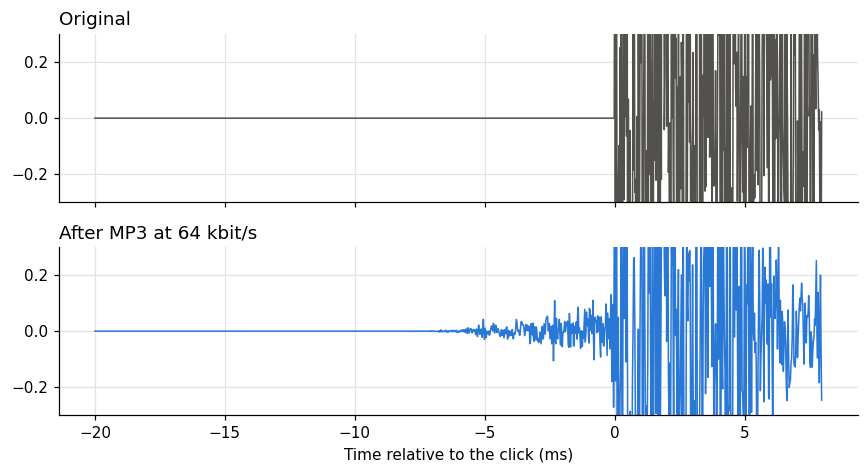

In [11]:
if shutil.which("ffmpeg"):
    s = 44100; t = np.arange(int(0.25 * s)) / s
    burst = rng.standard_normal(len(t)) * np.exp(-t / 0.02) * 0.8
    x = np.concatenate([np.zeros(int(0.5 * s)), burst, np.zeros(int(0.25 * s))]); onset = int(0.5 * s)
    out, _, _ = mp3_roundtrip(x, s, 64)
    lag = np.correlate(out[: s], x[: s], "full").argmax() - (s - 1)        # line the two up
    out = np.roll(out, -lag)[: len(x)]
    early = np.where(np.abs(out[:onset]) > np.abs(x).max() * 10 ** (-60 / 20))[0]
    print(f"noise starts {(onset - early.min()) / s * 1000:.1f} ms before the click")
    ms = (np.arange(len(x)) - onset) / s * 1000; w = slice(onset - int(0.02 * s), onset + int(0.008 * s))
    fig, axs = plt.subplots(2, 1, figsize=(8, 4.4), sharex=True, sharey=True)
    axs[0].plot(ms[w], x[w], color=INK2, lw=1); axs[0].set_title("Original", loc="left")
    axs[1].plot(ms[w], out[w], color=BLUE, lw=1); axs[1].set_title("After MP3 at 64 kbit/s", loc="left")
    axs[1].set_ylim(-0.3, 0.3); axs[1].set_xlabel("Time relative to the click (ms)"); plt.tight_layout(); plt.show()

## Where next

- The article this notebook belongs to, and the others in the set: [Music & AI on Medium](https://medium.com/@dorien-herremans/list/music-ai-3fb88d4826dd)
- The next notebook: [neural audio codecs](../02-neural-audio-codecs/notebook.ipynb)
- For the full picture: [A Tutorial on Generative Models for Music Audio](https://arxiv.org/abs/2610.38252)